# 2.9 Filtering and repairing records

📍 In-situ sensor · 🪨 Solid Earth · 📈 Seismology

🖥️ [**Diapositivas de la clase: manipular flujos de datos reales (sesión 08)**](https://geo-smart.github.io/mlgeo-book/slides/2026/lec08_repairing_records.html)

Archived records arrive with filter effects, gaps and timing errors. In this section you test three repairs on one real seismogram. The record is complete and correctly timed, so you damage a copy on purpose and grade every repair against the intact record with a number.

**The record.** On 29 July 2021 at 06:15:49 UTC the Mww 8.2 Chignik earthquake ruptured the plate interface between the Pacific and North America plates south of the Alaska Peninsula (USGS event ak0219neiszm; Mww: moment magnitude from the W phase). Broadband station UW.RATT of the Pacific Northwest Seismic Network (PNSN), at Rattlesnake Lake in the Cascade foothills east of Seattle, Washington, recorded it 2,627 km away on the WGS84 ellipsoid (World Geodetic System 1984), 23.56° of arc; the slides give 2,620 km, the same angle on a sphere at 111.2 km per degree. You use its vertical channel HHZ, 100 samples per second, from 06:15 to 08:15 UTC, the same record as section 2.8. The values are **raw digitizer counts**: no instrument correction. The station metadata (StationXML) give the sensitivity, 5.04 × 10⁸ counts per m/s at 1 Hz, so 1,000 counts is about 2 µm/s of ground velocity.

**Learning outcomes.** After this section you can:
- tell a step in a raw record from a seismic arrival, with a travel-time model;
- choose a causal or a zero-phase filter for a task, and measure what each does to an onset of known time;
- filter a record with a gap segment by segment, leave the gap marked as missing, and set a guard interval at its edges;
- measure a clock offset by cross-correlation against a reference, to a fraction of a sample;
- say which of these problems affects your own data, which repair you would apply, and what you would record about it.

**Objectives for today.** You will:
- load the course copy of the record and confirm its fingerprint;
- locate the P arrival and the first step in the raw record;
- filter the record causally and with zero phase, and compare the two at the step and at the P wave;
- plant a 20 s gap and a 0.5 s clock error on copies, repair each, and grade the repair against the intact record;
- write a short repair note for your project data.

| Part | Topic | Time |
|---|---|---|
| 1 | The record and its own problems | about 8 min |
| 2 | Filter phase | about 10 min |
| 3 | Gaps | about 12 min |
| 4 | Clock error | about 8 min |
| 5 | Your project's records | about 5 min |

The times are rough estimates of how long each part takes, not a schedule. The parts add to about 43 minutes and the lecture leaves about 38 for the notebook, so the real-gap cell in Part 3, the parabola step in Part 4 and the exercises are optional.

**Your-turn cells.** Write your code between `# --- your code` and `# --- end`. The last line checks it: it prints `correct` or a hint. Unless the answer is correct, the check puts the reference result in place of each name, keeps your own value as `<name>_yours` for comparison, and says so in one line, so the cells after it run from the reference. If your cell raises an error, comment out your lines and run it again. A worked solution, hidden, follows each one.

In [1]:
import hashlib
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import obspy
from obspy.geodetics import gps2dist_azimuth, locations2degrees
from obspy.taup import TauPyModel
from scipy import signal

import lab_29_checks as lab
from lab_29_checks import check_text, your_turn

SNAP = Path("snapshots")          # course copies, committed with the book
OFFLINE = bool(os.environ.get("CI")) or os.environ.get("MLGEO_OFFLINE") == "1"
PROV = json.loads((SNAP / "ratt_chignik_2021-07-29.provenance.json").read_text())
ev, sta = PROV["event"], PROV["station"]
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
print(f"{ev['title']}: {ev['origin_time_utc']}, {ev['latitude']:.2f}° N, {-ev['longitude']:.2f}° W, {ev['depth_km']} km deep")
print(f"UW.RATT, {sta['site']}: {sta['latitude']:.4f}° N, {-sta['longitude']:.4f}° W, {sta['elevation_m']} m")
print("offline mode:", OFFLINE)

M 8.2 - 2021 Chignik, Alaska Earthquake: 2021-07-29T06:15:49.188000Z, 55.36° N, 157.89° W, 35 km deep
UW.RATT, Rattlesnake Lake, King County, WA: 47.4255° N, 121.8025° W, 442.4 m
offline mode: True


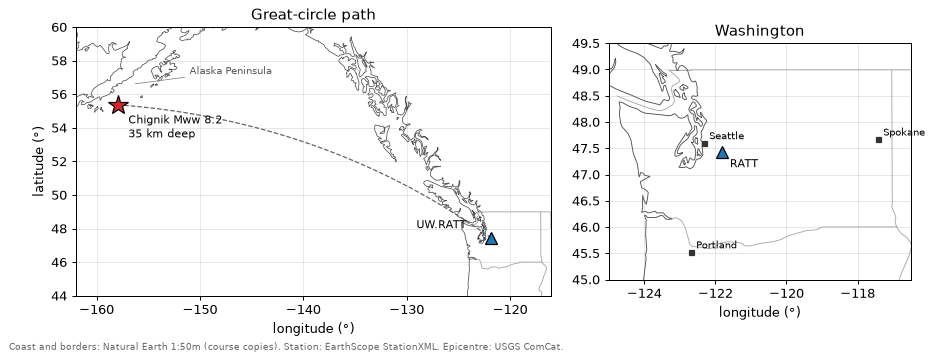

In [2]:
lab.draw_map(PROV, ev);

## Part 1. The record and its own problems (about 8 min)

**Do:** load the course copy, check it, locate the P wave, find the first step.

The course copy was downloaded from the EarthScope FDSN web services (FDSN: International Federation of Digital Seismograph Networks) on 13 October 2026. Its provenance file records each file's source URL and its **fingerprint** (SHA-256, Secure Hash Algorithm), a 64-character code computed from every byte. The next cell recomputes the fingerprints, then reads the waveform. You never write to the file: every damage below is done to a copy in memory.

In [3]:
for name, rec in PROV["files"].items():
    sha = hashlib.sha256((SNAP / name).read_bytes()).hexdigest()
    print("matches" if sha == rec["sha256"] else "DIFFERS", sha[:16] + "...", name)

st = obspy.read(str(SNAP / "ratt_chignik_2021-07-29_UW.RATT.HHZ_0615-0815.mseed"))
raw = st[0].data.astype(float)                 # raw counts, as archived
tr = st[0].copy()
tr.detrend("linear"); tr.taper(max_percentage=0.05)
z = tr.data.astype(float)                      # trend removed, 5% taper at each end: the record we filter
fs = tr.stats.sampling_rate
t = np.arange(len(z)) / fs                     # seconds after 06:15:00 UTC
print(tr.id, tr.stats.starttime, f"{len(z):,} samples at {fs:.0f} Hz")

matches 725e3b798e3a260c... ratt_chignik_2021-07-29_UW.RATT.HHZ_0415-0615.mseed
matches 3714a18f90478fbb... ratt_chignik_2021-07-29_UW.RATT.HHZ_0615-0815.mseed
matches ed6c4e695fd23694... ratt_chignik_2021-07-29_UW.RATT.3C_062630-062830.mseed
matches f3b9111403e4924e... ratt_chignik_2021-07-29_UW.RATT.stationxml.xml
matches 5712d99e125b4098... ratt_chignik_2021-07-29_usgs_ak0219neiszm.geojson
UW.RATT..HHZ 2021-07-29T06:15:00.000001Z 720,001 samples at 100 Hz


Where should the P wave be? The iasp91 Earth model (`obspy.taup`) gives the travel time for the USGS depth and the epicentral distance.

distance 2,627 km on the ellipsoid, 23.56° (2,620 km on a sphere)
origin 49.19 s after 06:15:00; iasp91 P travel time 307.3 s, so P at 356.5 s and S at 608.9 s
largest raw value 1.99 million counts


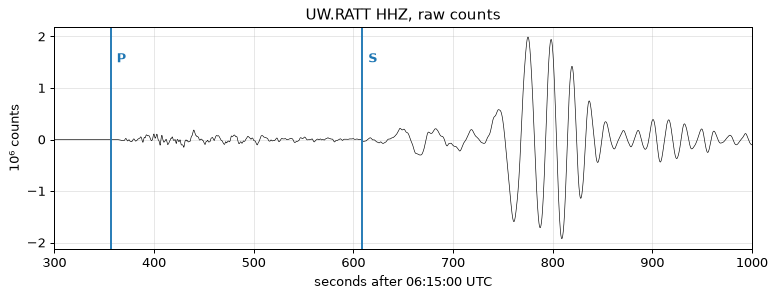

In [4]:
dist_m, _, _ = gps2dist_azimuth(ev["latitude"], ev["longitude"], sta["latitude"], sta["longitude"])
deg = locations2degrees(ev["latitude"], ev["longitude"], sta["latitude"], sta["longitude"])
origin = obspy.UTCDateTime(ev["origin_time_utc"]) - st[0].stats.starttime    # s after 06:15:00
arr = TauPyModel("iasp91").get_travel_times(ev["depth_km"], deg, ["P", "S"])
T_P = origin + min(a.time for a in arr if a.name == "P")
T_S = origin + min(a.time for a in arr if a.name == "S")
print(f"distance {dist_m / 1e3:,.0f} km on the ellipsoid, {deg:.2f}° ({deg * 111.195:,.0f} km on a sphere)")
print(f"origin {origin:.2f} s after 06:15:00; iasp91 P travel time {T_P - origin:.1f} s, so P at {T_P:.1f} s and S at {T_S:.1f} s")
print(f"largest raw value {np.abs(raw).max() / 1e6:.2f} million counts")
lab.plot_record(t, raw, T_P, T_S);

The P wave arrives about 357 s after 06:15 (307.3 s of travel; the lecture used a depth of 32 km, the USGS gives 35 km, a difference of 0.4 s). The surface waves dominate after 650 s, swinging by up to 2 million counts.

The raw record has a problem of its own. Between 755 and 832 s, on the steepest surface-wave swings, it carries eight **steps**: jumps of 1,600 to 3,600 counts, each completed within two or three samples and opposite in sign to the local slope. The cause is not identified, likely the instrument or the digitizer. An earlier version of this notebook called the first of them the "P-wave onset"; it comes about 400 s after the P wave.

**Your turn: find the first step.** Write `t_step`, the time (s after 06:15:00), after 700 s, where the slope of the raw record changes most abruptly. Try `np.diff(raw)` first and look where it peaks; then measure the change of slope instead.

*Hint:* `np.diff(raw, n=2)` is the change of slope; `np.argmax` of its absolute value after 700 s gives the step.

In [5]:
# --- your code
t_step = None    # seconds after 06:15:00, one number
# --- end
your_turn("1.step", globals())

[1.step] not answered yet
[t_step] using the reference result so the next cells run.


*Worked solution below (click ⋯ to open).*

In [6]:
# Worked solution, open after you tried
# Names end in _sol so that running this cell keeps your own results.
d2_sol = np.abs(np.diff(raw, n=2))     # d2_sol[i] is centred on sample i + 1
after_sol = t[1:-1] > 700
t_step_sol = t[1:-1][after_sol][np.argmax(d2_sol[after_sol])]
d1 = np.abs(np.diff(raw))
print(f"first difference peaks at {t[1:][t[1:] > 700][np.argmax(d1[t[1:] > 700])]:.2f} s, the steepest surface-wave swing")
print(f"second difference peaks at {t_step_sol:.2f} s, the first step")

first difference peaks at 803.77 s, the steepest surface-wave swing
second difference peaks at 755.09 s, the first step


step at 755.09 s, 399 s after the P arrival


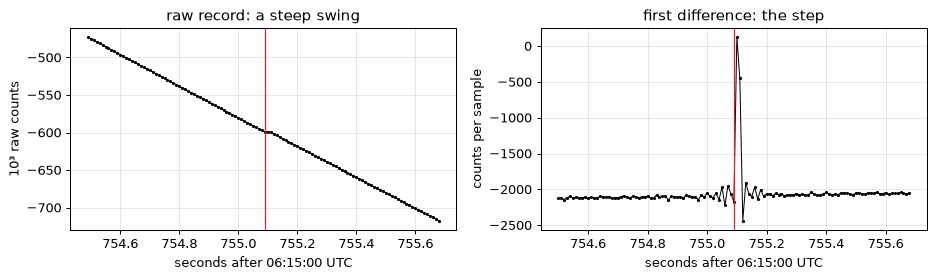

In [7]:
print(f"step at {t_step:.2f} s, {t_step - T_P:.0f} s after the P arrival")
lab.plot_step(t, raw, t_step, fs);

Look at the first difference just before the jump: from about 754.95 s it wiggles by about ±100 counts per sample. It looks like the ringing of the digitizer's own linear-phase anti-alias filter ahead of a sharp change, as on the Ali and others (2025) slide of the lecture; that cause is a reading of the figure, not tested here.

## Part 2. Filter phase (about 10 min)

**Do:** filter the record two ways and compare them where the true time is known.

A **causal** filter uses only the present and past samples (`signal.sosfilt`, one pass forward): its output cannot start before the input, but it shifts each frequency by a different amount, later above the band's centre and earlier below it. A **zero-phase** filter runs forward and then backward over the record (`signal.sosfiltfilt`): no delay, but its response is symmetric in time, so energy appears before a sharp onset. A P wave is emergent and buried in noise; the step at `t_step` is sharp and its time is known from the raw samples, so it measures what each filter does. Both use the 1 to 10 Hz band of the lecture 8 figures, a 2-pole Butterworth filter written as second-order sections (`sos`), which is numerically stable.

**Your turn: filter two ways.** Write `sos`, a 2-pole Butterworth band-pass from 1 to 10 Hz as second-order sections; `zf`, the zero-phase filtered `z`; and `zc`, the causal filtered `z`.

*Hint:* `signal.butter` with `output="sos"` and `fs=fs`; then `signal.sosfiltfilt` and `signal.sosfilt`.

In [8]:
# --- your code
sos = None    # your code
zf = None     # zero-phase, your code
zc = None     # causal, your code
# --- end
your_turn("2.filter", globals())

[2.filter] not answered yet
[sos, zf, zc] using the reference result so the next cells run.


*Worked solution below (click ⋯ to open).*

In [9]:
# Worked solution, open after you tried
# Names end in _sol so that running this cell keeps your own results.
sos_sol = signal.butter(2, [1, 10], "bandpass", fs=fs, output="sos")
zf_sol = signal.sosfiltfilt(sos_sol, z)
zc_sol = signal.sosfilt(sos_sol, z)

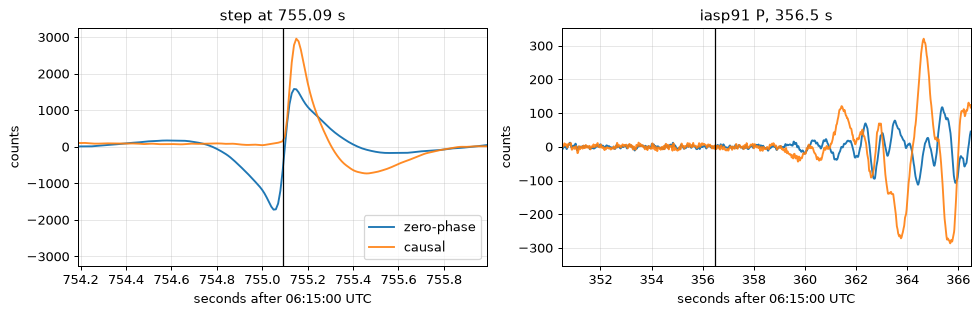

In [10]:
lab.plot_filters(t, zf, zc, t_step, T_P);

Measure what you see. The zero-phase output should start before the step; the causal output should peak after it.

**Your turn: measure the lead and the delay.** Write `lead_zp`, the time relative to `t_step` (negative before it) of the first sample between `t_step - 1` and `t_step + 0.5` s where `abs(zf)` exceeds 10% of its largest value there; and `delay_c`, the time relative to `t_step` of the largest `abs(zc)` in the 0.5 s after the step.

*Hint:* a boolean time window and `np.argmax` (on a boolean array it returns the first True).

In [11]:
# --- your code
lead_zp = None    # seconds, your code
delay_c = None    # seconds, your code
# --- end
your_turn("2.lead", globals())

[2.lead] not answered yet
[lead_zp, delay_c] using the reference result so the next cells run.


*Worked solution below (click ⋯ to open).*

In [12]:
# Worked solution, open after you tried
# Names end in _sol so that running this cell keeps your own results.
w_sol = (t >= t_step - 1) & (t < t_step + 0.5)
lead_zp_sol = t[w_sol][np.argmax(np.abs(zf[w_sol]) > 0.1 * np.abs(zf[w_sol]).max())] - t_step
post_sol = (t >= t_step) & (t < t_step + 0.5)
delay_c_sol = t[post_sol][np.argmax(np.abs(zc[post_sol]))] - t_step

In [13]:
pre, bg = (t >= t_step - 0.5) & (t < t_step - 0.01), (t >= t_step - 3) & (t < t_step - 1)
print(f"zero-phase output starts {lead_zp:+.2f} s from the step")
print(f"peaks after the step: zero-phase {lab.peak_after(t, zf, t_step):+.2f} s, causal {delay_c:+.2f} s")
print(f"in the 0.5 s before the step: zero-phase up to {np.abs(zf[pre]).max():,.0f} counts, causal "
      f"{np.abs(zc[pre]).max():,.0f}; background RMS {zf[bg].std():.0f} counts")

zero-phase output starts -0.52 s from the step
peaks after the step: zero-phase +0.05 s, causal +0.06 s
in the 0.5 s before the step: zero-phase up to 1,718 counts, causal 112; background RMS 45 counts


At the step, the zero-phase output starts about half a second early, with 1,700 counts against a background of 45: a picker run on it would place the onset early. The causal output stays at the background level until the step and peaks a few samples after it, reshaped. Its peak comes only about 0.01 s after the zero-phase one, because a step is dominated by the band's high frequencies, which a causal filter delays by a few hundredths of a second. The delay is different at each frequency, as the next cell shows.

In [14]:
freqs = [0.625, 1, 3, 5, 10]
phase, group = lab.filter_delays(sos, fs, freqs)
print("causal 1-10 Hz filter; negative means earlier")
for f_, ph, gd in zip(freqs, phase, group):
    print(f"  {f_:5.3f} Hz: phase delay {ph:+.3f} s, group delay {gd:+.3f} s")
on_c, n_c = lab.onset_above(t, zc)
on_z, n_z = lab.onset_above(t, zf)
print(f"first sample above 5 times its noise (standard deviation over 300-350 s): causal {on_c:.2f} s "
      f"(noise {n_c:.1f} counts), zero-phase {on_z:.2f} s (noise {n_z:.1f} counts); iasp91 P {T_P:.2f} s")

causal 1-10 Hz filter; negative means earlier
  0.625 Hz: phase delay -0.570 s, group delay +0.274 s
  1.000 Hz: phase delay -0.250 s, group delay +0.273 s
  3.000 Hz: phase delay -0.003 s, group delay +0.052 s
  5.000 Hz: phase delay +0.015 s, group delay +0.038 s
  10.000 Hz: phase delay +0.025 s, group delay +0.029 s
first sample above 5 times its noise (standard deviation over 300-350 s): causal 359.47 s (noise 4.9 counts), zero-phase 359.97 s (noise 3.5 counts); iasp91 P 356.49 s


At the P wave the two outputs differ more than at the step. Most P energy passed by this band lies near 0.6 to 1 Hz, below the band's centre, where a causal band-pass advances the phase (0.25 s at 1 Hz, 0.57 s at 0.6 Hz, printed above). So causal peaks come before zero-phase ones, while energy above 3 Hz is delayed by a few hundredths of a second. The causal output still never starts before the input.

The first P energy above five times the noise comes at 359.5 s in the causal output and 360.0 s in the zero-phase output (printed above), about 3 s after the iasp91 time. A one-dimensional Earth model can miss by that much, and the onset is emergent, its first wiggles the size of the noise. That is why the step, sharp and of known time, is the better test of a filter. The rule from the lecture: do not interpret small wiggles just before a sharp onset in zero-phase output, since the filter itself puts energy there.

Which to use depends on the task: real-time detection and studies of what happens before an onset (precursors, first motions) need a causal filter; aligning or stacking waveforms offline is done with zero phase. Either way, record the filter type, corners, number of poles, and causal or zero-phase with the data.

## Part 3. Gaps (about 12 min)

**Do:** plant a gap, filter across it, repair it, grade both against the intact record.

Telemetry drops out, disks fill, stations reboot. A careless merge fills the missing samples with zeros, which turns each edge into a step the size of the record's value there. Here you plant a 20 s gap from 850 to 870 s, inside the surface waves, on a copy.

In [15]:
gap = lab.GAP                                  # (850, 870) s after 06:15:00
i0, i1 = int(gap[0] * fs), int(gap[1] * fs)
z_gap = z.copy(); z_gap[i0:i1] = 0.0          # gap filled with zeros
zf_gap = signal.sosfiltfilt(sos, z_gap)       # filtered straight across the gap
z_nan = z.copy(); z_nan[i0:i1] = np.nan       # gap marked as missing
print(f"record at the edges: {z[i0 - 1]:,.0f} and {z[i1]:,.0f} counts; the 1-10 Hz signal there is a few tens of counts")

record at the edges: 95,994 and 156,500 counts; the 1-10 Hz signal there is a few tens of counts


**Your turn: filter segment by segment.** Write `zf_seg`: an array as long as `z_nan`, NaN inside the gap, and elsewhere each run of valid samples filtered on its own with `sos` and zero phase. Four to six lines.

*Hint:* `np.flatnonzero(~np.isnan(z_nan))` gives the valid indices; `np.split` them where `np.diff` of the indices exceeds 1.

In [16]:
# --- your code
zf_seg = None    # your code
# --- end
your_turn("3.segments", globals())

[3.segments] not answered yet
[zf_seg] using the reference result so the next cells run.


*Worked solution below (click ⋯ to open).*

In [17]:
# Worked solution, open after you tried
# Names end in _sol so that running this cell keeps your own results.
zf_seg_sol = np.full(len(z_nan), np.nan)
good_sol = np.flatnonzero(~np.isnan(z_nan))
for seg_sol in np.split(good_sol, np.flatnonzero(np.diff(good_sol) > 1) + 1):
    zf_seg_sol[seg_sol] = signal.sosfiltfilt(sos, z_nan[seg_sol])

Grade both methods against the intact record `zf`, over the 2 s outside each edge of the gap, where the damage is largest.

**Your turn: grade the two repairs.** Write `ratio_naive` and `ratio_seg`: the root-mean-square (RMS) difference from `zf` of `zf_gap` and of `zf_seg`, over the samples 0 to 2 s outside either edge, each divided by the RMS of `zf` over the same samples.

*Hint:* a boolean mask `near` of those samples, then `np.sqrt(np.mean(...**2))`.

In [18]:
# --- your code
ratio_naive = None    # your code
ratio_seg = None      # your code
# --- end
your_turn("3.grade", globals())

[3.grade] not answered yet
[ratio_naive, ratio_seg] using the reference result so the next cells run.


*Worked solution below (click ⋯ to open).*

In [19]:
# Worked solution, open after you tried
# Names end in _sol so that running this cell keeps your own results.
near_sol = ((t >= gap[0] - 2) & (t < gap[0])) | ((t >= gap[1]) & (t < gap[1] + 2))
sig_sol = np.sqrt(np.mean(zf[near_sol] ** 2))
ratio_naive_sol = np.sqrt(np.mean((zf_gap[near_sol] - zf[near_sol]) ** 2)) / sig_sol
ratio_seg_sol = np.sqrt(np.mean((zf_seg[near_sol] - zf[near_sol]) ** 2)) / sig_sol

edge error: filtered across the zero-filled gap 185 times the local signal; each segment alone 1.75 times


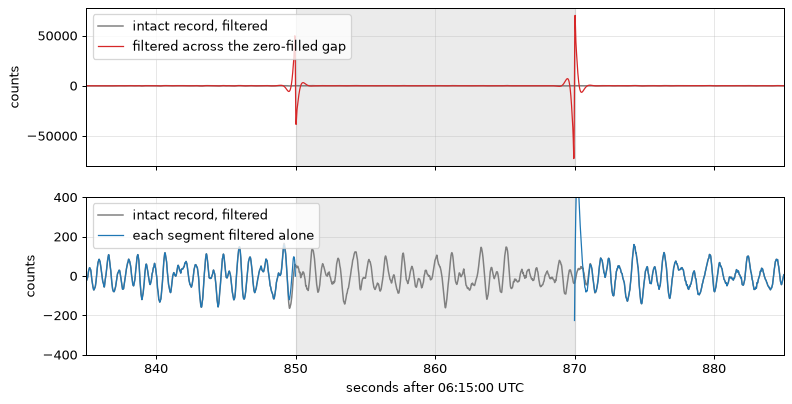

In [20]:
print(f"edge error: filtered across the zero-filled gap {ratio_naive:.0f} times the local signal; "
      f"each segment alone {ratio_seg:.2f} times")
lab.plot_gap(t, zf, zf_gap, zf_seg, gap);

The zero-filled gap makes the filter ring at both edges: a step contains all frequencies, and the band-pass answers at its corners. Within about 2 s of each edge, on both sides, the output rings at up to 40,000 counts, hundreds of times the local signal; a machine-learning model trained on windows cut across these edges would learn from the ringing. Filtering each segment alone and leaving the gap as NaN cuts the edge error by two orders of magnitude, and the gap stays declared as missing.

The remaining error near each edge is the filter's memory of the edge. How far does it reach? The **guard interval** is the stretch at each edge to leave out of later analysis (feature extraction in 2.11). The next cell measures how far from the gap the error exceeds 1% of the background, the RMS of the intact filtered record 5 to 60 s from the gap.

In [21]:
before, after, bg = lab.guard_interval(zf_seg, zf, t, gap)
guard, f_low = max(before, after), lab.BAND[0]
print(f"background 5 to 60 s from the gap: {bg:.0f} counts RMS")
print(f"error above 1% of it for {before:.1f} s before and {after:.1f} s after the gap: a guard of about "
      f"{np.ceil(guard):.0f} s, {guard * f_low:.1f} periods of the {f_low:g} Hz lower corner")

background 5 to 60 s from the gap: 166 counts RMS
error above 1% of it for 1.1 s before and 1.6 s after the gap: a guard of about 2 s, 1.6 periods of the 1 Hz lower corner


**Optional, online only: a real gap.** On 21 January 2021 at 17:48 UTC, UW.RATT HHZ lost 40 s of data in transmission; the archive holds two segments. The next cell fetches about 21 minutes around it from EarthScope and grades zero-filling against segment-by-segment filtering, as the lecture figure did (a peak edge error about 13 times the local signal, for about 1 s). Its guard is measured against the full local signal, not 1% of it as above, because the real record has no intact copy to grade against, only the segment-wise result. It is skipped when the notebook runs offline.

In [22]:
if OFFLINE:
    print("offline mode: skipped (online it downloads about 21 minutes of UW.RATT HHZ from EarthScope)")
else:
    try:
        lab.real_gap_at_ratt();
    except Exception as err:
        print("download failed, nothing lost: the planted gap above is the graded test.", err)

offline mode: skipped (online it downloads about 21 minutes of UW.RATT HHZ from EarthScope)


## Part 4. Clock error (about 10 min)

**Do:** shift a copy by 0.5 s and recover the shift.

When a station's GPS clock loses lock, its time stamps drift. The waveform is unchanged and looks perfect; every arrival time, every pick used as a label, every travel time is wrong. The repair measures the lag against a reference and corrects the time stamps. Here the copy is shifted by 50 samples (`np.roll` wraps the last 50 samples to the start, far from the window used), and the reference is the intact record, over a 60 s window on the P wave train (355 to 415 s).

**Your turn: shift a copy.** Write `z_late`, a copy of `z` with every sample moved 0.5 s later (50 samples), and `zf_late`, its zero-phase 1 to 10 Hz filtered version with `sos`.

*Hint:* `np.roll`; 0.5 s is `0.5 * fs` samples.

In [23]:
# --- your code
z_late = None     # your code
zf_late = None    # your code
# --- end
your_turn("4.shift", globals())

[4.shift] not answered yet
[z_late, zf_late] using the reference result so the next cells run.


*Worked solution below (click ⋯ to open).*

In [24]:
# Worked solution, open after you tried
# Names end in _sol so that running this cell keeps your own results.
z_late_sol = np.roll(z, int(round(0.5 * fs)))
zf_late_sol = signal.sosfiltfilt(sos, z_late_sol)

In [25]:
w0, w1 = int(lab.P_WINDOW[0] * fs), int(lab.P_WINDOW[1] * fs)
a, b = zf[w0:w1], zf_late[w0:w1]                       # reference window and late window

**Your turn: cross-correlate.** Write `cc`, the full cross-correlation of the late window `b` with the reference `a`; `lags`, the lag of each value in seconds; and `lag_peak`, the lag of the largest value.

*Hint:* `signal.correlate`, `signal.correlation_lags`, `np.argmax`; put the late window first.

In [26]:
# --- your code
cc = None          # your code
lags = None        # seconds, your code
lag_peak = None    # seconds, your code
# --- end
your_turn("4.lag", globals())

[4.lag] not answered yet
[cc, lags, lag_peak] using the reference result so the next cells run.


*Worked solution below (click ⋯ to open).*

In [27]:
# Worked solution, open after you tried
# Names end in _sol so that running this cell keeps your own results.
cc_sol = signal.correlate(b, a, mode="full")
lags_sol = signal.correlation_lags(len(b), len(a), mode="full") / fs
lag_peak_sol = lags_sol[np.argmax(cc_sol)]

The peak sample gives the lag to the nearest sample, ±0.005 s. The next step is optional. A parabola through the peak and its two neighbours places the maximum between samples. With y0, y1, y2 the values at j − 1, j, j + 1, the vertex lies 0.5 (y0 − y2) / (y0 − 2 y1 + y2) samples from j.

**Your turn: refine with a parabola (optional).** Write `lag_sub`, the lag in seconds at the vertex of the parabola through the three values of `cc` around its peak.

*Hint:* `np.argmax(cc)` gives the peak index j; the formula above gives the offset from j in samples.

In [28]:
# --- your code
lag_sub = None    # seconds, your code
# --- end
your_turn("4.sub", globals())

[4.sub] not answered yet
[lag_sub] using the reference result so the next cells run.


*Worked solution below (click ⋯ to open).*

In [29]:
# Worked solution, open after you tried
# Names end in _sol so that running this cell keeps your own results.
j_sol = np.argmax(cc)
y0_sol, y1_sol, y2_sol = cc[j_sol - 1], cc[j_sol], cc[j_sol + 1]
lag_sub_sol = lag_peak + 0.5 * (y0_sol - y2_sol) / (y0_sol - 2 * y1_sol + y2_sol) / fs

planted +0.50 s; peak sample +0.50 s; parabola +0.500 s


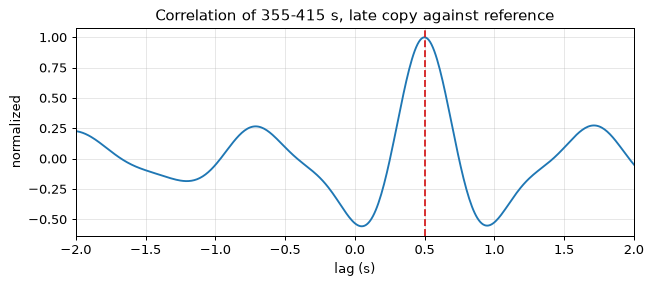

In [30]:
lab.plot_correlation(lags, cc, lag_peak, lab.P_WINDOW);
print(f"planted {lab.SHIFT_S:+.2f} s; peak sample {lag_peak:+.2f} s; parabola {lag_sub:+.3f} s")

The recovery is exact by construction: the late copy is the reference itself, shifted, so the waveforms match perfectly. This shows the method, not its accuracy. On real data the reference is a co-located sensor, a neighbour station (after removing the predicted travel-time difference), or the correlation of ambient noise between two stations, tracked day by day. The lecture showed two such cases:

- **Seafloor clock drift.** Naranjo and others (2024, *Seismica*, [doi:10.26443/seismica.v3i1.367](https://doi.org/10.26443/seismica.v3i1.367)) correlated ambient noise (0.2 to 0.4 Hz) between ocean-bottom station O01 and land station RET off Iceland. O01's clock was already 0.31 s off at deployment, so a straight line from zero to the clock difference measured at recovery (−1.02 s) overcorrects; fitting both an offset and a drift aligns the correlations.
- **A 270 s timing error at US.HDIL, Illinois.** GPS timing was lost from 3 October 2022 to 6 March 2023. Noise correlation with station N4.N41A, 133 km away, shows the lag growing to +270 s by February, and the P wave of the February 2023 Kahramanmaraş earthquake arrives +269.9 s late at HDIL, against +1.2 s at the neighbour P43A.

## Part 5. Your project's records (about 5 min)

**Do:** write three short answers about the data of your team project.

Which of the three problems (filter phase, gaps, clock error) applies to your data, and where would you see it? Which repair would you apply? What would you write down about it so that someone else can redo it: for example the filter type, corners and phase; the start, end and fill value of each gap and the guard interval; the timing reference, the lag or drift found, and the correction applied.

In [31]:
q5_problem = ""    # which problem, in which part of your data
q5_repair = ""     # the repair you would apply
q5_record = ""     # what you would write down about it
check_text("5.problem", q5_problem); check_text("5.repair", q5_repair); check_text("5.record", q5_record)

[5.problem] not answered yet
[5.repair] not answered yet
[5.record] not answered yet


## Exercises (if you have time)

**1. A gap in the P wave train.** The next cell plants the gap at 360 to 420 s, on the P wave train (task 2 of the lecture), and grades both methods with `lab.edge_error`, as in Part 3. Change `gap2` to try other places. Why is the zero-filled error, relative to the local signal, much smaller than in the surface waves?

In [32]:
gap2 = (360.0, 420.0)
j0, j1 = int(gap2[0] * fs), int(gap2[1] * fs)
z_gap2 = z.copy(); z_gap2[j0:j1] = 0.0
z_nan2 = z.copy(); z_nan2[j0:j1] = np.nan
for name, test in [("zero-filled", signal.sosfiltfilt(sos, z_gap2)), ("segments", lab.filter_segments(z_nan2, sos))]:
    err, local2 = lab.edge_error(test, zf, t, gap2)
    print(f"gap {gap2[0]:.0f}-{gap2[1]:.0f} s, {name}: {err / local2:.2f} times the local signal ({local2:.0f} counts RMS)")

gap 360-420 s, zero-filled: 2.06 times the local signal (559 counts RMS)
gap 360-420 s, segments: 0.05 times the local signal (559 counts RMS)


**2. A longer period band.** Redo Part 3 in a 0.1 to 1 Hz band. Write `sos2`, then run the cell: it refilters the intact record and both repairs in the new band and measures the guard interval. The grading window grows to 20 s (`width=20`), because a 2 s window would sit inside the new guard. How does the guard scale with the lower corner frequency?

In [33]:
sos2 = None    # your code: a 2-pole Butterworth band-pass from 0.1 to 1 Hz, as in Part 2
if sos2 is None:
    print("set sos2 first")
else:
    zf2 = signal.sosfiltfilt(sos2, z)
    for name, test in [("zero-filled", signal.sosfiltfilt(sos2, z_gap)), ("segments", lab.filter_segments(z_nan, sos2))]:
        err, local2 = lab.edge_error(test, zf2, t, gap, width=20)
        print(f"0.1-1 Hz, {name}: {err / local2:.2f} times the local signal over 0 to 20 s from the edges")
    before2, after2, bg2 = lab.guard_interval(lab.filter_segments(z_nan, sos2), zf2, t, gap)
    g2 = max(before2, after2)
    print(f"guard {before2:.1f} s before and {after2:.1f} s after the gap: {g2 * 0.1:.1f} periods of the 0.1 Hz corner")

set sos2 first


*Expected, from the worked line `sos2 = signal.butter(2, [0.1, 1], "bandpass", fs=fs, output="sos")`: zero-filled about 0.6 times and segments about 0.3 times the local signal; a guard of about 11 s before and 10 s after the gap, about one period of the lower corner.*

**3. A clock error between samples.** A shift of exactly 50 samples leaves the parabola little to do. The next cell plants a shift of 0.537 s by multiplying the spectrum by a phase ramp, so that the shift falls between samples. Repeat your Part 4 lines on the window `b3` against `a`: what do the peak sample and the parabola give?

In [34]:
f = np.fft.rfftfreq(len(z), 1 / fs)
z_frac = np.fft.irfft(np.fft.rfft(z) * np.exp(-2j * np.pi * f * 0.537), n=len(z))   # 0.537 s later
b3 = signal.sosfiltfilt(sos, z_frac)[w0:w1]
# your code: cross-correlate b3 with a, take the peak sample, then the parabola

In [35]:
# Worked solution, open after you tried
cc3 = signal.correlate(b3, a, mode="full")
lags3 = signal.correlation_lags(len(b3), len(a), mode="full") / fs
k = np.argmax(cc3)
sub3 = lags3[k] + 0.5 * (cc3[k - 1] - cc3[k + 1]) / (cc3[k - 1] - 2 * cc3[k] + cc3[k + 1]) / fs
print(f"planted +0.537 s; peak sample {lags3[k]:+.3f} s; parabola {sub3:+.4f} s")

planted +0.537 s; peak sample +0.540 s; parabola +0.5367 s


**Data and credit.** Waveforms and station metadata: UW network, University of Washington (1963), Pacific Northwest Seismic Network, [doi:10.7914/SN/UW](https://doi.org/10.7914/SN/UW). Data were accessed from the NSF NGF data archive operated by EarthScope Consortium (NSF award 2435260). Earthquake parameters: USGS ComCat event [ak0219neiszm](https://earthquake.usgs.gov/earthquakes/eventpage/ak0219neiszm), public domain. Coastlines and borders: Natural Earth, public domain; `snapshots/naturalearth_npacific_coast.csv` is built by `snapshots/make_naturalearth_npacific_coast.py`. Course copies of the seismic data, their source URLs and fingerprints: `snapshots/ratt_chignik_2021-07-29.provenance.json`, built by `snapshots/make_ratt_chignik_2021-07-29.py`.